In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')

print(f'NumPy      version: {np.__version__}')
print(f'pandas     version: {pd.__version__}')
print(f'TensorFlow version: {tf.__version__}')
print('Imports successful.')

NumPy      version: 2.4.6
pandas     version: 2.2.3
TensorFlow version: 2.21.0
Imports successful.


In [2]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


def make_windows(X, window_size=32, step=4):
    """
    Extracts overlapping sliding windows from a (T, F) sensor array.
    Returns (windows, starts) where windows.shape = (N, window_size, F).
    """
    T       = X.shape[0]
    starts  = np.arange(0, T - window_size + 1, step)
    windows = np.stack([X[s : s + window_size] for s in starts])
    return windows, starts


def reconstruction_error(model, X, window_size=32, step=4):
    """
    Computes per-window MSE reconstruction error for a sensor array.
    Returns (errors, indices) where errors.shape = (N,).
    """
    windows, indices = make_windows(X, window_size, step)
    reconstructed    = model.predict(windows.astype(np.float32), verbose=0)
    errors = np.mean((windows - reconstructed) ** 2, axis=(1, 2))
    return errors, indices


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


In [3]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)
    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1
    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


synth_dir  = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

print('Synthetic SKAB dataset ready.')

# Load or retrain model
SENSOR_COLS = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
               'Pressure', 'Temperature', 'Thermocouple',
               'Voltage', 'Volume Flow RateRMS']
WINDOW_SIZE = 32
STEP        = 4
DATA_DIR    = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
MODEL_PATH  = Path('autoencoder_week05.keras')

if MODEL_PATH.exists():
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f'Model loaded from {MODEL_PATH}')
else:
    print('Model file not found — retraining from scratch...')
    def build_autoencoder(window_size=32, n_features=8):
        inp = keras.Input(shape=(window_size, n_features))
        x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(inp)
        x = keras.layers.MaxPooling1D(2)(x)
        x = keras.layers.Conv1D(8,  3, activation='relu', padding='same')(x)
        x = keras.layers.MaxPooling1D(2)(x)
        x = keras.layers.Conv1D(8,  3, activation='relu', padding='same')(x)
        x = keras.layers.UpSampling1D(2)(x)
        x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(x)
        x = keras.layers.UpSampling1D(2)(x)
        out = keras.layers.Conv1D(n_features, 3, activation='linear', padding='same')(x)
        m = keras.Model(inp, out)
        m.compile(optimizer='adam', loss='mse')
        return m
    df_clean = pd.read_csv(DATA_DIR / '3.csv', sep=';',
                           index_col='datetime', parse_dates=True)
    X_clean  = df_clean[SENSOR_COLS].values.astype(np.float32)
    X_train, _ = make_windows(X_clean, WINDOW_SIZE, STEP)
    tf.random.set_seed(42); np.random.seed(42)
    model = build_autoencoder(WINDOW_SIZE, X_train.shape[2])
    model.fit(X_train, X_train, epochs=15, batch_size=16,
              validation_split=0.1, verbose=1)
    model.save(MODEL_PATH)
    print(f'Model saved to {MODEL_PATH}')

print('Ready.')

Synthetic SKAB dataset ready.
Model file not found — retraining from scratch...
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.5137 - val_loss: 0.4985
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4921 - val_loss: 0.4833
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4761 - val_loss: 0.4668
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4565 - val_loss: 0.4450
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4321 - val_loss: 0.4181
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4027 - val_loss: 0.3878
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3705 - val_loss: 0.3569
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3392 - val_loss: 0.3265
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3111 - val_loss: 0.3001
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2873 - val_loss: 0.2782
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2660 - val_loss: 0.2593
Epoch

In [4]:
df_clean   = pd.read_csv(DATA_DIR / '3.csv', sep=';',
                         index_col='datetime', parse_dates=True)
X_clean    = df_clean[SENSOR_COLS].values.astype(np.float32)
errors_train, _ = reconstruction_error(model, X_clean, WINDOW_SIZE, STEP)

print(f'Training errors shape: {errors_train.shape}')
print(f'Min  : {errors_train.min():.6f}')
print(f'Mean : {errors_train.mean():.6f}')
print(f'95th : {np.percentile(errors_train, 95):.6f}')
print(f'99th : {np.percentile(errors_train, 99):.6f}')
print(f'Max  : {errors_train.max():.6f}')

Training errors shape: (143,)
Min  : 0.119450
Mean : 0.192774
95th : 0.273869
99th : 0.289821
Max  : 0.293122


In [5]:
def set_threshold(errors_clean, percentile=99):
    """
    Sets an anomaly detection threshold from clean reconstruction errors.

    Parameters
    ----------
    errors_clean : np.ndarray (N,) — MSE errors on clean training windows
    percentile   : float in (0, 100) — threshold percentile (default 99)

    Returns
    -------
    threshold : float
    """
    # TODO: return float(np.percentile(errors_clean, percentile))
    return float(np.percentile(errors_clean, percentile))


threshold_99 = set_threshold(errors_train, percentile=99)
threshold_95 = set_threshold(errors_train, percentile=95)
print(f'99th-percentile threshold: {threshold_99:.6f}')
print(f'95th-percentile threshold: {threshold_95:.6f}')
assert isinstance(threshold_99, float), 'threshold must be a Python float'
assert threshold_99 > 0, 'threshold must be positive'
print('set_threshold() checks passed.')

99th-percentile threshold: 0.289821
95th-percentile threshold: 0.273869
set_threshold() checks passed.


In [9]:
def predict_anomalies(errors, indices, threshold, T, window_size):
    """
    Maps per-window binary predictions back to a timestep array.

    Parameters
    ----------
    errors      : np.ndarray (N,) — reconstruction error per window
    indices     : np.ndarray (N,) int — start index of each window
    threshold   : float
    T           : int — total number of timesteps in the file
    window_size : int

    Returns
    -------
    pred : np.ndarray (T,) int — 1 = predicted anomaly, 0 = predicted normal
    """
    # TODO: initialize pred = np.zeros(T, dtype=int)
    # TODO: for each (err, start) in zip(errors, indices):
    #         compute center = start + window_size // 2
    #         if center < T: pred[center] = int(err > threshold)
    # TODO: return pred
    pred = np.zeros(T, dtype=int)

    for err, start in zip(errors, indices):
        center = start + window_size // 2

        if center < T:
            pred[center] = int(err > threshold)

    return pred

# Quick check on contaminated 4.csv
df4    = pd.read_csv(DATA_DIR / '4.csv', sep=';',
                     index_col='datetime', parse_dates=True)
X4     = df4[SENSOR_COLS].values.astype(np.float32)
labels4 = df4['anomaly'].values.astype(int)
windows4 = extract_anomaly_windows(labels4)

np.random.seed(42)
X4_cont = X4.copy()
for s, e in windows4:
    X4_cont = inject_noise_profile(X4_cont, s, e, variance=2.5, mode='noise')

err4, idx4 = reconstruction_error(model, X4_cont, WINDOW_SIZE, STEP)
pred4 = predict_anomalies(err4, idx4, threshold_99, len(labels4), WINDOW_SIZE)

assert pred4.shape == labels4.shape, f'Shape mismatch: {pred4.shape} vs {labels4.shape}'
assert pred4.dtype == int or np.issubdtype(pred4.dtype, np.integer), 'pred must be integer'
assert set(np.unique(pred4)).issubset({0, 1}), 'pred must contain only 0s and 1s'
print(f'predict_anomalies() shape check passed: {pred4.shape}')
print(f'Predicted anomaly timesteps (4.csv contaminated): {pred4.sum()}')



predict_anomalies() shape check passed: (900,)
Predicted anomaly timesteps (4.csv contaminated): 93


In [11]:
def compute_metrics(labels, pred):
    """
    Computes precision, recall, and F1 from binary arrays.

    Parameters
    ----------
    labels : np.ndarray (T,) int — ground-truth anomaly labels
    pred   : np.ndarray (T,) int — predicted anomaly labels

    Returns
    -------
    dict with keys: tp, fp, fn, precision, recall, f1
    """
    # TODO: tp = int(np.sum((pred == 1) & (labels == 1)))
    # TODO: fp = int(np.sum((pred == 1) & (labels == 0)))
    # TODO: fn = int(np.sum((pred == 0) & (labels == 1)))
    # TODO: precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    # TODO: recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    # TODO: f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    # TODO: return dict(tp=tp, fp=fp, fn=fn, precision=precision, recall=recall, f1=f1)
    tp = int(np.sum((pred == 1) & (labels == 1)))
    fp = int(np.sum((pred == 1) & (labels == 0)))
    fn = int(np.sum((pred == 0) & (labels == 1)))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else 0.0)

    return dict(
        tp=tp,
        fp=fp,
        fn=fn,
        precision=precision,
        recall=recall,
        f1=f1
    )


m4 = compute_metrics(labels4, pred4)
print(f'4.csv (contaminated) — P={m4["precision"]:.3f}  R={m4["recall"]:.3f}  F1={m4["f1"]:.3f}')
print(f'  TP={m4["tp"]}  FP={m4["fp"]}  FN={m4["fn"]}')
assert isinstance(m4['precision'], float), 'precision must be float'
assert 0.0 <= m4['precision'] <= 1.0, 'precision out of range'
assert 0.0 <= m4['recall'] <= 1.0, 'recall out of range'
assert 0.0 <= m4['f1'] <= 1.0, 'F1 out of range'
print('compute_metrics() checks passed.')

4.csv (contaminated) — P=0.516  R=0.253  F1=0.339
  TP=48  FP=45  FN=142
compute_metrics() checks passed.


In [12]:
def evaluate_file(model, filepath, sensor_cols, threshold,
                  window_size=32, step=4, noise_variance=2.5, seed=42):
    """
    Evaluates the autoencoder on one SKAB CSV file.
    Contaminates anomaly windows with noise before evaluation.

    Parameters
    ----------
    model          : trained keras.Model
    filepath       : Path
    sensor_cols    : list[str]
    threshold      : float
    window_size    : int
    step           : int
    noise_variance : float
    seed           : int

    Returns
    -------
    dict — one row of the results scorecard
    """
    # TODO: read CSV with pd.read_csv(filepath, sep=';', index_col='datetime', parse_dates=True)
    # TODO: extract X (sensor values) and labels (anomaly column), compute T = len(labels)
    # TODO: use extract_anomaly_windows + inject_noise_profile to contaminate anomaly windows
    # TODO: call reconstruction_error(model, X_cont, window_size, step) → errors, indices
    # TODO: call predict_anomalies(errors, indices, threshold, T, window_size) → pred
    # TODO: call compute_metrics(labels, pred) → metrics dict
    # TODO: add filename, threshold, n_anomaly_ts, n_windows to metrics and return it
    df = pd.read_csv(
        filepath,
        sep=';',
        index_col='datetime',
        parse_dates=True
    )

    X = df[sensor_cols].values.astype(np.float32)
    labels = df['anomaly'].values.astype(int)
    T = len(labels)

    windows = extract_anomaly_windows(labels)

    np.random.seed(seed)

    X_cont = X.copy()

    for s, e in windows:
        X_cont = inject_noise_profile(
            X_cont,
            s,
            e,
            variance=noise_variance,
            mode='noise'
        )

    errors, indices = reconstruction_error(
        model,
        X_cont,
        window_size,
        step
    )

    pred = predict_anomalies(
        errors,
        indices,
        threshold,
        T,
        window_size
    )

    metrics = compute_metrics(labels, pred)

    metrics.update(dict(
        filename=filepath.name,
        threshold=threshold,
        n_anomaly_ts=int(labels.sum()),
        n_windows=len(errors)
    ))

    return metrics


# Run evaluation on all files
THRESHOLD = threshold_99
results   = []

for fname, _, _ in files_spec:
    row = evaluate_file(
        model, DATA_DIR / fname, SENSOR_COLS, THRESHOLD,
        WINDOW_SIZE, STEP
    )
    results.append(row)
    print(f"{row['filename']:8s}  anomaly_ts={row['n_anomaly_ts']:3d}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['f1']:.3f}")

results_df = pd.DataFrame(results)[[
    'filename', 'n_anomaly_ts', 'tp', 'fp', 'fn',
    'precision', 'recall', 'f1', 'threshold'
]]
print('\nScorecard:')
print(results_df.to_string(index=False))

# Key assertions
row3 = next(r for r in results if r['filename'] == '3.csv')
assert row3['f1'] == 0.0, f'3.csv has no anomalies — F1 must be 0.0, got {row3["f1"]}'
print('\nAssertion passed: 3.csv F1 = 0.0 (no anomalies in clean file).')

files_with_anomalies = [r for r in results if r['n_anomaly_ts'] > 0]
f1_nonzero = [r for r in files_with_anomalies if r['f1'] > 0.0]
assert len(f1_nonzero) > 0, 'At least one file with anomalies must have F1 > 0'
print(f'Assertion passed: {len(f1_nonzero)}/{len(files_with_anomalies)} anomalous files have F1 > 0.')



1.csv     anomaly_ts=160  P=0.597  R=0.250  F1=0.352
2.csv     anomaly_ts=150  P=0.422  R=0.253  F1=0.317
3.csv     anomaly_ts=  0  P=0.000  R=0.000  F1=0.000
4.csv     anomaly_ts=190  P=0.516  R=0.253  F1=0.339
5.csv     anomaly_ts=120  P=0.612  R=0.250  F1=0.355

Scorecard:
filename  n_anomaly_ts  tp  fp  fn  precision   recall       f1  threshold
   1.csv           160  40  27 120   0.597015 0.250000 0.352423   0.289821
   2.csv           150  38  52 112   0.422222 0.253333 0.316667   0.289821
   3.csv             0   0   2   0   0.000000 0.000000 0.000000   0.289821
   4.csv           190  48  45 142   0.516129 0.252632 0.339223   0.289821
   5.csv           120  30  19  90   0.612245 0.250000 0.355030   0.289821

Assertion passed: 3.csv F1 = 0.0 (no anomalies in clean file).
Assertion passed: 4/4 anomalous files have F1 > 0.


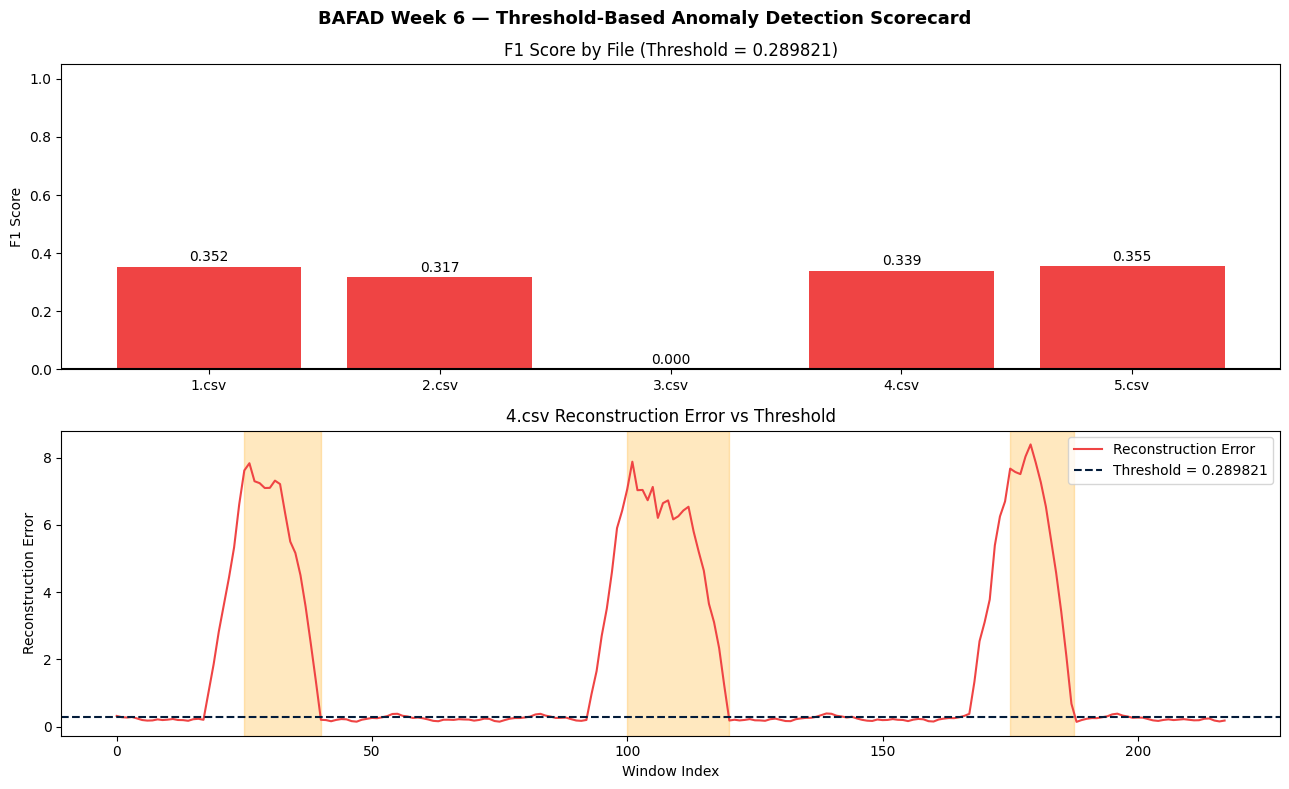

Plot saved to week06_exercise1_plot.png


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

filenames = [r['filename'] for r in results]
f1_scores = [r['f1'] for r in results]
colors    = ['#EF4444' if f > 0 else '#94A3B8' for f in f1_scores]

# TODO: Bar chart on axes[0] — bar(filenames, f1_scores, color=colors)
#       Add axhline(0), ylabel='F1 Score', title with threshold value, ylim(0,1.05)
#       Add text labels above each bar: axes[0].text(i, f+0.02, f'{f:.3f}', ...)

# TODO: Reload 4.csv, contaminate it (seed=42, variance=2.5), compute reconstruction error
#       Plot error on axes[1] (color='#EF4444')
#       Add axhline(THRESHOLD, color='#021B3A', linestyle='--', label=...)
#       Add axvspan shading for anomaly windows; ylabel, xlabel, legend
# Bar chart
axes[0].bar(filenames, f1_scores, color=colors)

axes[0].axhline(0, color='black')
axes[0].set_ylabel('F1 Score')
axes[0].set_title(
    f'F1 Score by File (Threshold = {THRESHOLD:.6f})'
)
axes[0].set_ylim(0, 1.05)

for i, f in enumerate(f1_scores):
    axes[0].text(i, f + 0.02, f'{f:.3f}', ha='center')


# Reload 4.csv
df4 = pd.read_csv(
    DATA_DIR / '4.csv',
    sep=';',
    index_col='datetime',
    parse_dates=True
)

X4 = df4[SENSOR_COLS].values.astype(np.float32)

labels4 = df4['anomaly'].values.astype(int)

windows4 = extract_anomaly_windows(labels4)

np.random.seed(42)

X4_cont = X4.copy()

for s, e in windows4:
    X4_cont = inject_noise_profile(
        X4_cont,
        s,
        e,
        variance=2.5,
        mode='noise'
    )

err4, idx4 = reconstruction_error(
    model,
    X4_cont,
    WINDOW_SIZE,
    STEP
)

axes[1].plot(
    err4,
    color='#EF4444',
    label='Reconstruction Error'
)

axes[1].axhline(
    THRESHOLD,
    color='#021B3A',
    linestyle='--',
    label=f'Threshold = {THRESHOLD:.6f}'
)

for s, e in windows4:
    axes[1].axvspan(
        s / STEP,
        e / STEP,
        color='orange',
        alpha=0.25
    )

axes[1].set_ylabel('Reconstruction Error')
axes[1].set_xlabel('Window Index')
axes[1].set_title('4.csv Reconstruction Error vs Threshold')
axes[1].legend()

fig.suptitle('BAFAD Week 6 — Threshold-Based Anomaly Detection Scorecard',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('week06_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week06_exercise1_plot.png')



Q1. The threshold is set at the 99th percentile of clean training errors. What does this choice imply about the expected false positive rate on clean test data?

This means that the expected false possitive rate there should be is about 1%. This makes less false alarms overall.

Q2. File 3.csv has zero anomaly rows. What values do you expect for precision, recall, and F1 after running evaluate_file() on it? Explain why.

3.csv should have a precision of 0.0, recall of 0.0, and F1 of 0.0. This is because there are no true possitives to detect in the file.

Q3. A student changes the threshold from the 99th to the 50th percentile. Describe what happens to precision and recall on the anomalous files, and explain the direction of each change.

Doing this will produce much more recall activity. We will see much more true anomolies, but also much more normal points classified as an anomoly.So while we will find more anomolies, we will also be bombarded with false alarms resulting in decreasing precision.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
